# Application of LASSO: Predicting Diabetes Progression

**The question.** A clinic records 10 baseline measurements for each diabetes patient. Which of them are worth collecting to predict how far the disease will progress over the next year?

**Two goals**

1. Predict well on patients the model has not seen.
2. Use as few measurements as possible.

**Why LASSO?** It minimizes

$$\text{RSS} + \lambda \sum_j |\beta_j|$$

The penalty sets some coefficients to exactly 0, so one model does both prediction and variable selection.

*In scikit-learn, $\lambda$ is called `alpha`, and RSS is divided by $2n$, so `alpha` is on a different scale from a hand-worked $\lambda$.*

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, LassoCV, lasso_path
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.titlesize": 13, "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
BLUE, GRAY = "#2a78d6", "#c3c2b7"

## The data

442 patients, from the study behind the original LARS paper (Efron et al., 2004). It comes with scikit-learn, so there is nothing to download.

| Column | Meaning | Column | Meaning |
|:--|:--|:--|:--|
| `age`, `sex` | Age in years, sex (coded 1/2) | `hdl` | HDL ("good") cholesterol |
| `bmi` | Body mass index | `tch` | Total cholesterol / HDL |
| `bp` | Average blood pressure | `ltg` | Log of serum triglycerides (possibly) |
| `tc` | Total serum cholesterol | `glu` | Blood sugar |
| `ldl` | LDL ("bad") cholesterol | **`y`** | **Progression score, one year later** |

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True, scaled=False)
X = X.rename(columns={"s1": "tc", "s2": "ldl", "s3": "hdl", "s4": "tch", "s5": "ltg", "s6": "glu"})
y.name = "progression"

print(X.shape)
pd.concat([X, y], axis=1).head()

(442, 10)


,age,sex,bmi,bp,tc,ldl,hdl,tch,ltg,glu,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


## Giving the model many candidates

The effect of one measurement may depend on another, so we also offer every **square** and **interaction**, such as `bmi bp`. Choosing among that many terms by hand is impractical, and this is where LASSO helps.

We standardize before building the products so that an interaction does not just copy its parents. We then standardize again so all terms are on the same scale.

In [3]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

def make_prep():
    return make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
    ).set_output(transform="pandas")

# sex has only two values, so sex^2 carries the same information as sex
prep = make_prep()
X_train = prep.fit_transform(X_train_raw).drop(columns="sex^2")
X_test = prep.transform(X_test_raw).drop(columns="sex^2")

print("Candidate terms:", X_train.shape[1])
print("Training patients:", X_train.shape[0], "  Test patients:", X_test.shape[0])
print("First few:", list(X_train.columns[:12]))

Candidate terms: 64
Training patients: 309   Test patients: 133
First few: ['age', 'sex', 'bmi', 'bp', 'tc', 'ldl', 'hdl', 'tch', 'ltg', 'glu', 'age^2', 'age sex']


## Baseline: linear regression with all 64 terms

In [4]:
ols_all = LinearRegression().fit(X_train, y_train)

print(f"Train R2 = {r2_score(y_train, ols_all.predict(X_train)):.3f}")
print(f"Test  R2 = {r2_score(y_test, ols_all.predict(X_test)):.3f}")

Train R2 = 0.638
Test  R2 = 0.212


The large gap between train and test is **overfitting**. With every term in the model, it fits noise in the training patients. It also fails our second goal, since it uses all 10 measurements.

## LASSO: let cross-validation choose `alpha`

In [5]:
lasso = LassoCV(cv=5, random_state=1, max_iter=50000).fit(X_train, y_train)
coefs = pd.Series(lasso.coef_, index=X_train.columns)

print(f"Chosen alpha = {lasso.alpha_:.2f}")
print(f"Terms kept   = {(coefs != 0).sum()} of {len(coefs)}")
print(f"Train R2     = {r2_score(y_train, lasso.predict(X_train)):.3f}")
print(f"Test  R2     = {r2_score(y_test, lasso.predict(X_test)):.3f}")

Chosen alpha = 4.04
Terms kept   = 12 of 64
Train R2     = 0.554
Test  R2     = 0.414


LASSO closes most of that gap and drops most of the terms.

## How `alpha` was chosen, and a simpler option

The curve is nearly flat around its minimum, so many values of `alpha` predict about equally well.

The **one-standard-error rule** uses this: take the largest `alpha` whose error is within one standard error of the minimum. That gives a simpler model with little loss in accuracy.

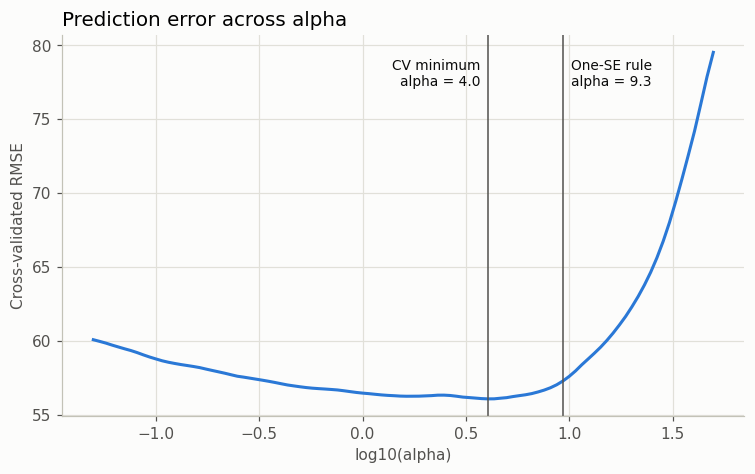

In [6]:
def one_se_alpha(cv_model):
    mean_mse = cv_model.mse_path_.mean(axis=1)
    se_mse = cv_model.mse_path_.std(axis=1, ddof=1) / np.sqrt(cv_model.mse_path_.shape[1])
    best = mean_mse.argmin()
    return cv_model.alphas_[mean_mse <= mean_mse[best] + se_mse[best]].max()

alpha_simple = one_se_alpha(lasso)
cv_rmse = np.sqrt(lasso.mse_path_.mean(axis=1))

fig, ax = plt.subplots()
ax.plot(np.log10(lasso.alphas_), cv_rmse, color=BLUE, lw=2)
for a, label, dx, side in [(lasso.alpha_, "CV minimum", -5, "right"), (alpha_simple, "One-SE rule", 5, "left")]:
    ax.axvline(np.log10(a), color="#52514e", lw=1)
    ax.annotate(f"{label}\nalpha = {a:.1f}", (np.log10(a), cv_rmse.max()), xytext=(dx, -4), ha=side,
                textcoords="offset points", va="top", color="#0b0b0b", fontsize=9)
ax.set(xlabel="log10(alpha)", ylabel="Cross-validated RMSE", title="Prediction error across alpha")
plt.show()

## The LASSO path: terms drop out as `alpha` grows

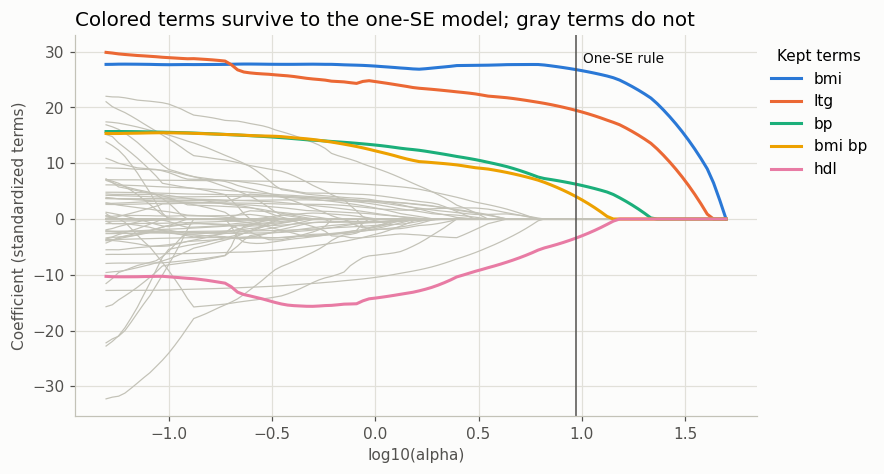

In [7]:
alphas, path, _ = lasso_path(X_train, y_train, max_iter=50000)
path = pd.DataFrame(path, index=X_train.columns)

simple_lasso = Lasso(alpha=alpha_simple, max_iter=50000).fit(X_train, y_train)
simple_coefs = pd.Series(simple_lasso.coef_, index=X_train.columns)
kept = simple_coefs[simple_coefs != 0].sort_values(key=abs, ascending=False)

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
fig, ax = plt.subplots()
for term in path.index.difference(kept.index):
    ax.plot(np.log10(alphas), path.loc[term], color=GRAY, lw=0.8)
for term, color in zip(kept.index, colors):
    ax.plot(np.log10(alphas), path.loc[term], color=color, lw=2, label=term)
ax.axvline(np.log10(alpha_simple), color="#52514e", lw=1)
ax.annotate("One-SE rule", (np.log10(alpha_simple), path.values.max()), xytext=(5, 0),
            textcoords="offset points", va="top", color="#0b0b0b", fontsize=9)
ax.set(xlabel="log10(alpha)", ylabel="Coefficient (standardized terms)",
       title="Colored terms survive to the one-SE model; gray terms do not")
ax.legend(title="Kept terms", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## The simple model

alpha = 9.33, terms kept = 5 of 64


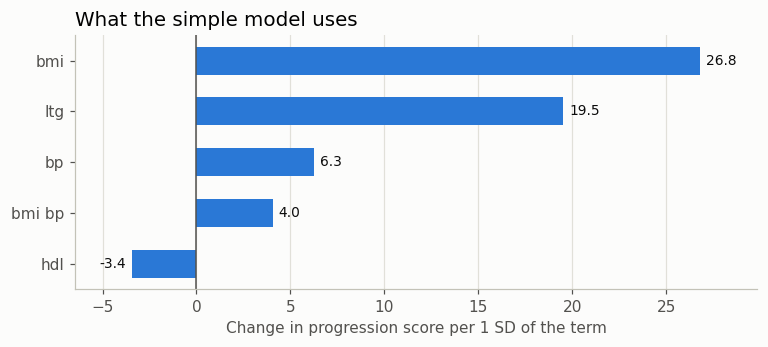

In [8]:
print(f"alpha = {alpha_simple:.2f}, terms kept = {len(kept)} of {len(simple_coefs)}")

fig, ax = plt.subplots(figsize=(8, 3))
ordered = kept.iloc[::-1]
bars = ax.barh(ordered.index, ordered.values, color=BLUE, height=0.55)
ax.bar_label(bars, fmt="%.1f", padding=4, color="#0b0b0b", fontsize=9)
ax.axvline(0, color="#52514e", lw=1)
ax.margins(x=0.1)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Change in progression score per 1 SD of the term", title="What the simple model uses")
plt.show()

- **Four measurements are enough:** `bmi`, `ltg`, `bp` and `hdl`. The fifth term, `bmi bp`, is built from two of them, so the clinic could skip the other six.
- Higher BMI, triglycerides and blood pressure go with more progression. Higher HDL goes with less.
- The positive `bmi bp` term means high BMI and high blood pressure together add more risk than each one alone suggests.

## Comparing the models on the test set

In [9]:
ols_10 = LinearRegression().fit(X_train_raw, y_train)

def row(name, n_terms, pred):
    return {"Model": name, "Terms used": n_terms,
            "Test R2": r2_score(y_test, pred),
            "Test RMSE": mean_squared_error(y_test, pred) ** 0.5}

pd.DataFrame([
    row("Regression, 64 terms", 64, ols_all.predict(X_test)),
    row("Regression, 10 original measurements", 10, ols_10.predict(X_test_raw)),
    row("LASSO, CV minimum", (coefs != 0).sum(), lasso.predict(X_test)),
    row("LASSO, one-SE rule", len(kept), simple_lasso.predict(X_test)),
]).set_index("Model").round(3)

,Terms used,Test R2,Test RMSE
Model,,,
"Regression, 64 terms",64,0.212,62.968
"Regression, 10 original measurements",10,0.438,53.170
"LASSO, CV minimum",12,0.414,54.301
"LASSO, one-SE rule",5,0.385,55.654


LASSO is far better than regression on all 64 terms. It does **not** beat the plain 10-measurement regression here. Its gain is reaching similar accuracy with fewer terms, without us choosing them by hand. The one-SE model gives up a little accuracy for that simplicity.

## Using the model on new patients

Two made-up patients, for illustration only. Only the four kept measurements affect the score, so the other six are filled in with training averages.

In [10]:
new_patients = pd.DataFrame([X_train_raw.mean(), X_train_raw.mean()], index=["Patient A", "Patient B"])
new_patients[["bmi", "bp", "ltg", "hdl"]] = [[22, 80, 4.2, 60], [35, 110, 5.5, 35]]

features = prep.transform(new_patients).drop(columns="sex^2")
result = new_patients[["bmi", "bp", "ltg", "hdl"]].copy()
result["Predicted progression"] = simple_lasso.predict(features).round(0)
result

,bmi,bp,ltg,hdl,Predicted progression
Patient A,22.0,80.0,4.2,60.0,103.0
Patient B,35.0,110.0,5.5,35.0,252.0


## Try it: change `alpha`

Change the value and re-run. Try 0.1, 1, 5, 10, 20 and 50. Which value would you report to the clinic?

In [11]:
alpha = 5

model = Lasso(alpha=alpha, max_iter=50000).fit(X_train, y_train)
terms = pd.Series(model.coef_, index=X_train.columns)
terms = terms[terms != 0].sort_values(key=abs, ascending=False)

print(f"alpha = {alpha}:  {len(terms)} terms kept,  test R2 = {r2_score(y_test, model.predict(X_test)):.3f}")
print(terms.round(1).to_string())

alpha = 5:  9 terms kept,  test R2 = 0.404
bmi        27.7
ltg        21.4
bp          8.7
bmi bp      7.8
hdl        -6.9
sex        -2.3
age sex     1.1
glu^2       0.7
age glu     0.7


## Would we get the same answer on different patients?

One split can be lucky, so we repeat everything on 50 random train/test splits. This cell takes about 10 to 20 seconds to run.

In [12]:
scores, kept_runs = [], []
for seed in range(50):
    a_raw, b_raw, a_y, b_y = train_test_split(X, y, test_size=0.3, random_state=seed)
    p = make_prep()
    a = p.fit_transform(a_raw).drop(columns="sex^2")
    b = p.transform(b_raw).drop(columns="sex^2")

    cv = LassoCV(cv=5, random_state=1, max_iter=50000).fit(a, a_y)
    simple = Lasso(alpha=one_se_alpha(cv), max_iter=50000).fit(a, a_y)

    scores.append({
        "Regression, 64 terms": r2_score(b_y, LinearRegression().fit(a, a_y).predict(b)),
        "Regression, 10 measurements": r2_score(b_y, LinearRegression().fit(a_raw, a_y).predict(b_raw)),
        "LASSO, CV minimum": r2_score(b_y, cv.predict(b)),
        "LASSO, one-SE rule": r2_score(b_y, simple.predict(b)),
    })
    kept_runs.append(pd.Series(simple.coef_ != 0, index=a.columns))

scores = pd.DataFrame(scores)
kept_share = pd.concat(kept_runs, axis=1).mean(axis=1).sort_values(ascending=False)
n_terms = pd.concat(kept_runs, axis=1).sum()

print(scores.agg(["mean", "std"]).T.round(3).rename(columns={"mean": "Mean test R2", "std": "SD"}))
print(f"\nLASSO beat the 64-term regression in {(scores['LASSO, CV minimum'] > scores['Regression, 64 terms']).mean():.0%} of splits")
print(f"One-SE model size: {n_terms.min()} to {n_terms.max()} terms, average {n_terms.mean():.1f}")

                             Mean test R2     SD
Regression, 64 terms                0.312  0.111
Regression, 10 measurements         0.471  0.050
LASSO, CV minimum                   0.473  0.052
LASSO, one-SE rule                  0.447  0.047

LASSO beat the 64-term regression in 100% of splits
One-SE model size: 3 to 12 terms, average 7.1


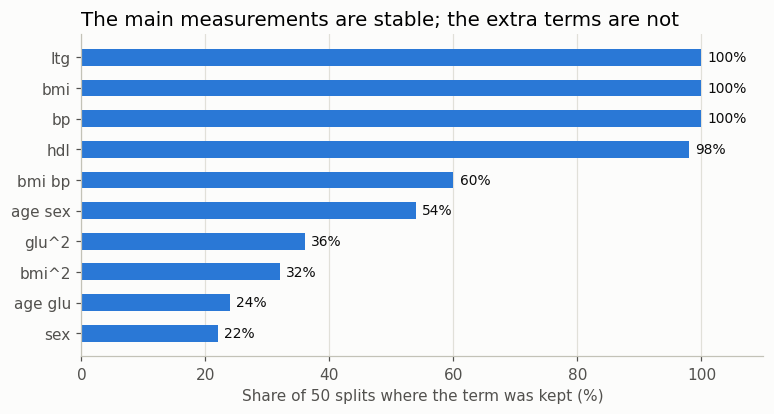

In [13]:
top = kept_share.head(10).iloc[::-1] * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(top.index, top.values, color=BLUE, height=0.55)
ax.bar_label(bars, fmt="%.0f%%", padding=4, color="#0b0b0b", fontsize=9)
ax.set_xlim(0, 110)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Share of 50 splits where the term was kept (%)",
       title="The main measurements are stable; the extra terms are not")
plt.show()

`bmi`, `ltg`, `bp` and `hdl` are kept almost every time. The other terms come and go, so the exact list from a single split should not be treated as the one true model.

## Takeaways

- **Selection and prediction together:** LASSO narrowed 64 candidates to a short list and predicted far better than regression on all 64.
- **Not automatically the most accurate:** it only tied a plain regression on the 10 measurements. Always compare against a simple baseline.
- **You choose the trade-off:** the CV minimum favors accuracy, and the one-SE rule favors simplicity.
- **Check stability:** rerun on other splits before trusting a selected variable. Correlated measurements, such as `tc` and `ldl`, can replace one another.
- **Prediction is not causation:** a kept term is useful for predicting, which does not show that changing it would change the outcome. Coefficients are also shrunk toward 0 by design.